06 10 月实盘窗口评估
修改下面的 `LIVE_START` / `LIVE_END` 即可。**参数只用 LIVE_START 之前的数据选出并冻结**，然后从 LIVE_START 开盘建仓模拟。

10/24 之后重新下载 CSV 覆盖 `etf_daily.csv`，再从头运行即可。

若 CSV 尚未覆盖结束日，展示已有日期，明确标注未完成窗口。

在 PyCharm 中选择 Python 内核，点击 **Run All / 运行全部**。最后一格调用 `main()`，无需手动逐个调用函数。


In [1]:
from pathlib import Path
import os
import json

def find_pipeline_dir():
    """支持从项目根目录、pipeline 目录及项目内子目录启动。"""
    roots = ([Path(os.environ['ETF_PROJECT_ROOT']).expanduser()] if os.environ.get('ETF_PROJECT_ROOT') else [])
    roots += [Path.cwd(), *Path.cwd().parents]
    for root in roots:
        for candidate in (root / 'pipeline', root):
            if (candidate / '00_engine.ipynb').is_file() and (candidate / '07_run_pipeline.ipynb').is_file():
                return candidate.resolve()
    raise FileNotFoundError('找不到 pipeline 文件夹。请将 PyCharm 工作目录设为项目根目录，或设置 ETF_PROJECT_ROOT。')

PIPELINE_DIR = find_pipeline_dir()

def load_notebook_definitions(filename):
    """独立命名空间加载函数；不执行被加载 notebook 的入口单元格。"""
    path = PIPELINE_DIR / filename
    notebook = json.loads(path.read_text(encoding='utf-8'))
    namespace = {'__name__': 'pipeline_module'}
    for number, item in enumerate(notebook['cells']):
        if item['cell_type'] == 'code' and 'pipeline-entry' not in item.get('metadata', {}).get('tags', []):
            exec(compile(''.join(item['source']), f'{path}:cell{number}', 'exec'), namespace)
    return namespace

_engine = load_notebook_definitions('00_engine.ipynb')
for _name, _value in _engine.items():
    if not _name.startswith('_'):
        globals()[_name] = _value


In [2]:
def evaluate_october(O, H, L, C, tg, runs, LIVE_START, LIVE_END):
    idx=C.index
    prev=idx[idx<pd.Timestamp(LIVE_START)][-1]          # 实盘开始前最后一个收盘日
    best,sc=select(runs,IS_START,str(prev.date()))
    print(f'用 {prev.date()} 及以前的数据选参（冻结）:',label(best),'| 数据最后一天:',idx[-1].date())
    res={};rows=[]
    for n,c in [('基线（无止损止盈）',base),('选中参数',best)]:
        eq,tr=backtest(O,H,L,C,tg,c[1],c[2],c[0],5,10,start=str(prev.date()))
        e=eq.loc[str(prev.date()):LIVE_END]; res[n]=e
        rows.append({'方案':n,'区间':f'{e.index[1].date()}~{e.index[-1].date()}','交易日':len(e)-1,'累计收益':f'{e.iloc[-1]/e.iloc[0]-1:+.2%}','最大回撤':f'{(e/e.cummax()-1).min():.2%}'})
    for t in ['SPY','TQQQ']:
        e=C[t].loc[str(prev.date()):LIVE_END]
        rows.append({'方案':'买入持有 '+t,'区间':f'{e.index[1].date()}~{e.index[-1].date()}','交易日':len(e)-1,'累计收益':f'{e.iloc[-1]/e.iloc[0]-1:+.2%}','最大回撤':f'{(e/e.cummax()-1).min():.2%}'})
    table = pd.DataFrame(rows)
    display(table)
    print('信号（每日收盘时的目标持仓）:'); display(tg.loc[str(prev.date()):LIVE_END].to_frame('target').T)
    df=pd.DataFrame(res).round(4); display(df)
    df.set_axis(['Baseline','Selected'],axis=1).plot(figsize=(8,3.5),title='Live-window equity'); plt.show()
    return {'best': best, 'metrics': table, 'equity': df, 'signals': tg.loc[str(prev.date()):LIVE_END]}


In [3]:
def main(csv_path=None, context=None, runs=None, live_start='2026-10-01', live_end='2026-10-24'):
    """本 notebook 的一键入口；返回表格、净值等结果。"""
    context = prepare_context(csv_path) if context is None else context
    O, H, L, C, tg = context
    runs = run_all(*context) if runs is None else runs
    if pd.Timestamp(live_end) < pd.Timestamp(live_start):
        raise ValueError('LIVE_END 不得早于 LIVE_START。')
    if C.index[C.index < pd.Timestamp(live_start)].empty or C.loc[live_start:live_end].empty:
        print('10 月窗口尚无可用数据，跳过。')
        return {'status': 'skipped', 'reason': 'insufficient window data'}
    if C.index[-1] < pd.Timestamp(live_end):
        print(f'窗口未完成：计划结束 {live_end}，当前数据截至 {C.index[-1].date()}。')
    return evaluate_october(*context, runs, live_start, live_end)


数据区间: 2011-10-03 ~ 2026-10-07 | 信号分布: {'TQQQ': 2904, 'TECL': 249, 'TECS': 203, 'BSV': 150, 'UVXY': 133, 'SPXL': 17}


窗口未完成：计划结束 2026-10-24，当前数据截至 2026-10-07。
用 2026-09-30 及以前的数据选参（冻结）: 固定 止损=0.12 止盈=0.15 | 数据最后一天: 2026-10-07


,方案,区间,交易日,累计收益,最大回撤
0,基线（无止损止盈）,2026-10-01~2026-10-07,5,+5.96%,-0.75%
1,选中参数,2026-10-01~2026-10-07,5,+5.96%,-0.75%
2,买入持有 SPY,2026-10-01~2026-10-07,5,+1.91%,-0.24%
3,买入持有 TQQQ,2026-10-01~2026-10-07,5,+7.16%,-0.75%


信号（每日收盘时的目标持仓）:


,2026-09-30,2026-10-01,2026-10-02,2026-10-05,2026-10-06,2026-10-07
target,TQQQ,TQQQ,TQQQ,TQQQ,TQQQ,TQQQ


,基线（无止损止盈）,选中参数
2026-09-30,1.0000,1.0000
2026-10-01,0.9976,0.9976
2026-10-02,1.0265,1.0265
2026-10-05,1.0532,1.0532
2026-10-06,1.0675,1.0675
2026-10-07,1.0596,1.0596


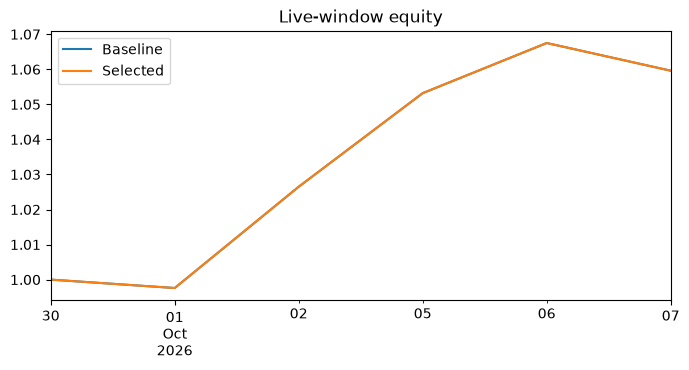

In [4]:
CSV_PATH = None
LIVE_START = '2026-10-01'
LIVE_END = '2026-10-24'
results = main(csv_path=CSV_PATH, live_start=LIVE_START, live_end=LIVE_END)
